# Chapitre 11 - Cours 7 : jointures de flux et tolérance aux pannes

Ce dernier cours couvre les sous-sections *Stream Joins* (*Stream-stream join (window
join)*, *Stream-table join (stream enrichment)*, *Table-table join (materialized view
maintenance)*, *Time-dependence of joins*) et *Fault Tolerance* (*Microbatching and
checkpointing*, *Atomic commit revisited*, *Idempotence*, *Rebuilding state after a
failure*). Les opérateurs de jointure (`SearchClickJoin`, `enrich`, `TimelineView`) et le
job à état avec pannes injectées (`run_stateful_job`, `FencedSink`) sont dans
[`ddia/streams.py`](../../ddia/streams.py).

**Plan.**

1. Jointure flux-flux : recherches et clics.
2. Jointure flux-table : enrichir un flux.
3. Jointure table-table : maintenir des timelines.
4. La dépendance temporelle des jointures.
5. Micro-lots et points de contrôle.
6. La validation atomique revisitée.
7. L'idempotence (et le fencing).
8. Reconstruire l'état après une panne.

In [1]:
import sqlite3

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ddia import streams as st
from ddia.diagrams import Diagram
from ddia.timelines import SpaceTime
from ddia.plotting import (AMBER, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET,
                           annotate_bars, finish, set_style, subtitle)

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 3)
rng = np.random.default_rng(0)

## 1. Jointure flux-flux (section *Stream-stream join (window join)*)

Les jobs par lots joignent des jeux de données par clé (chapitre 10) ; le
traitement de flux, qui généralise les pipelines au cas incrémental et non borné, a le
même besoin, compliqué par le fait que de nouveaux événements peuvent arriver à tout
moment. Trois cas se présentent : flux-flux, flux-table, table-table.

**Flux-flux.** Un moteur de recherche enregistre un événement à chaque recherche et un
autre à chaque clic sur un résultat. Pour calculer le **taux de clic** (click-through
rate) de chaque résultat, il faut réunir les deux événements, liés par l'identifiant de
session (même besoin dans la publicité). Le clic peut ne jamais venir (recherche
abandonnée), venir après quelques secondes ou après des jours (onglet oublié), et même
arriver **avant** la recherche à cause des délais réseau. On choisit donc une **fenêtre**
de jointure, par exemple une heure. Notez qu'embarquer les détails de la recherche dans
l'événement de clic ne remplace pas la jointure : on ne connaîtrait que les recherches
cliquées, jamais celles qui ne l'ont pas été, donc aucun taux.

L'opérateur garde un **état** : les événements de la dernière heure, indexés par
session. À chaque recherche ou clic, il l'ajoute à l'index correspondant et consulte
l'autre index ; si la paire est complète, il émet « tel résultat a été cliqué ». Si une
recherche expire sans clic, il émet « non cliqué ». Simulons 8 000 sessions sur deux
heures : 40 % cliquent, après un délai log-normal (médiane 20 s, avec une longue queue),
et chaque événement subit un délai réseau aléatoire.

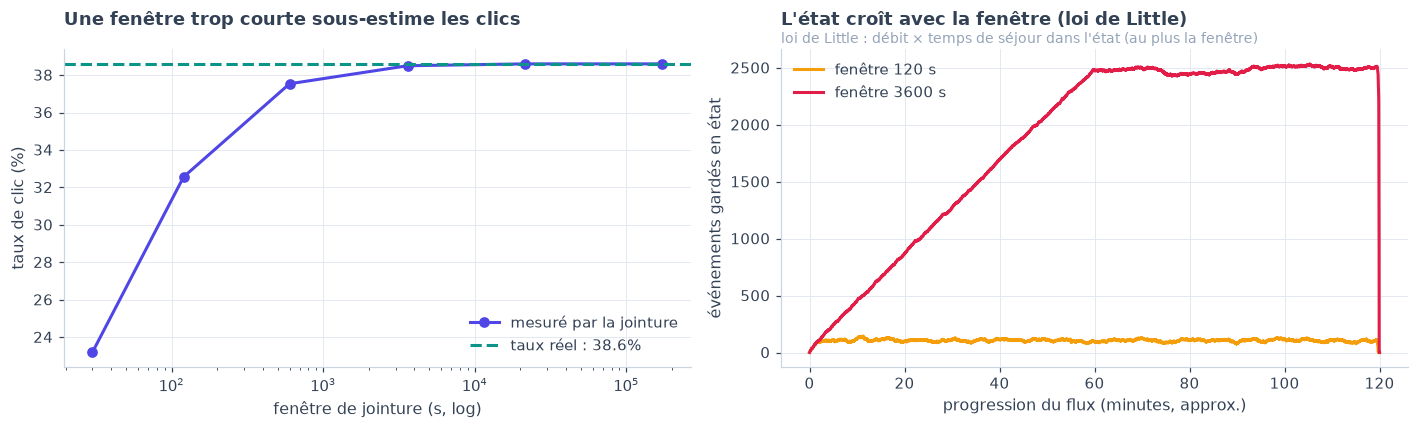

,taux de clic mesuré,état max (événements)
fenêtre,,
30,0.232,55
120,0.326,144
600,0.375,491
3600,0.385,2535
21600,0.386,4957
172800,0.386,4957


In [2]:
n_sess = 8000
t_search = np.sort(rng.uniform(0, 7200, n_sess))
clique = rng.random(n_sess) < 0.4
delai_clic = rng.lognormal(np.log(20), 1.8, n_sess)
evts = []                                                  # (arrivée, kind, session, t_événement)
for s in range(n_sess):
    evts.append((t_search[s] + rng.lognormal(0, 1), "search", s, t_search[s]))
    if clique[s]:
        tc = t_search[s] + delai_clic[s]
        evts.append((tc + rng.lognormal(0, 1), "click", s, tc))
evts.sort()
rows, etats = [], {}
for W in [30, 120, 600, 3600, 6 * 3600, 48 * 3600]:
    j = st.SearchClickJoin(window=W)
    for _, kind, s, t in evts:
        j.process(kind, s, t)
    j.flush()
    oui = sum(o[0] == "clicked" for o in j.out)
    non = sum(o[0] == "not_clicked" for o in j.out)
    rows.append({"fenêtre": W, "taux de clic mesuré": oui / (oui + non), "état max (événements)": max(j.state_size)})
    etats[W] = j.state_size
J = pd.DataFrame(rows).set_index("fenêtre")
fig, (ax, ax2) = plt.subplots(1, 2, figsize=(13, 4))
ax.semilogx(J.index, J["taux de clic mesuré"] * 100, "o-", color=INDIGO, label="mesuré par la jointure")
ax.axhline(clique.mean() * 100, color=TEAL, ls="--", label=f"taux réel : {clique.mean():.1%}")
ax.set_xlabel("fenêtre de jointure (s, log)"); ax.set_ylabel("taux de clic (%)")
ax.set_title("Une fenêtre trop courte sous-estime les clics")
ax.legend(loc="lower right")
for W, c in [(120, AMBER), (3600, ROSE)]:
    ax2.plot(np.arange(len(etats[W])) / len(etats[W]) * 7200 / 60, etats[W], color=c, label=f"fenêtre {W} s")
ax2.set_xlabel("progression du flux (minutes, approx.)"); ax2.set_ylabel("événements gardés en état")
ax2.set_title("L'état croît avec la fenêtre (loi de Little)")
subtitle(ax2, "loi de Little : débit × temps de séjour dans l'état (au plus la fenêtre)")
ax2.legend()
plt.tight_layout(); plt.show()
J.round(3)

Avec une fenêtre de 30 secondes, on rate la majorité des clics tardifs et l'on mesure un
taux de clic bien inférieur au taux réel (23 % au lieu de 38,6 %) ; il faut une fenêtre
d'environ une heure pour capter presque tous les clics de la longue queue. Mais l'état
grandit proportionnellement : d'après la loi de Little, il vaut le débit des événements
multiplié par leur temps de séjour dans l'état, qui atteint la fenêtre entière pour toutes
les recherches qui ne seront jamais cliquées. Le choix de la
fenêtre est donc un compromis entre exactitude et mémoire, et dépend de la distribution
des délais (exercice 11.10).

> **À retenir.** Une jointure flux-flux garde les événements récents des deux flux,
> indexés par clé, sur une fenêtre ; elle émet les paires et les absences de paire. La
> fenêtre arbitre entre exactitude et taille de l'état.

## 2. Jointure flux-table (section *Stream-table join (stream enrichment)*)

Un flux d'activité contient des identifiants d'utilisateurs ; on veut y ajouter des
informations de profil : c'est l'**enrichissement**. Interroger une base distante pour
chaque événement serait lent et risquerait de la surcharger. Mieux vaut charger une
**copie locale** de la table dans l'opérateur (table de hachage en mémoire si elle est
petite, index sur disque local sinon) : c'est une **jointure par hachage**. Différence avec
le traitement par lots : l'opérateur tourne longtemps et la table change, donc la copie
locale doit être tenue à jour, par **CDC** : l'opérateur s'abonne au journal des
changements des profils en plus du flux d'activité. On obtient une jointure entre deux
flux, où le flux de la table a une fenêtre qui remonte « au début des temps » (les
nouvelles versions écrasant les anciennes), et le flux d'activité pas de fenêtre du tout.

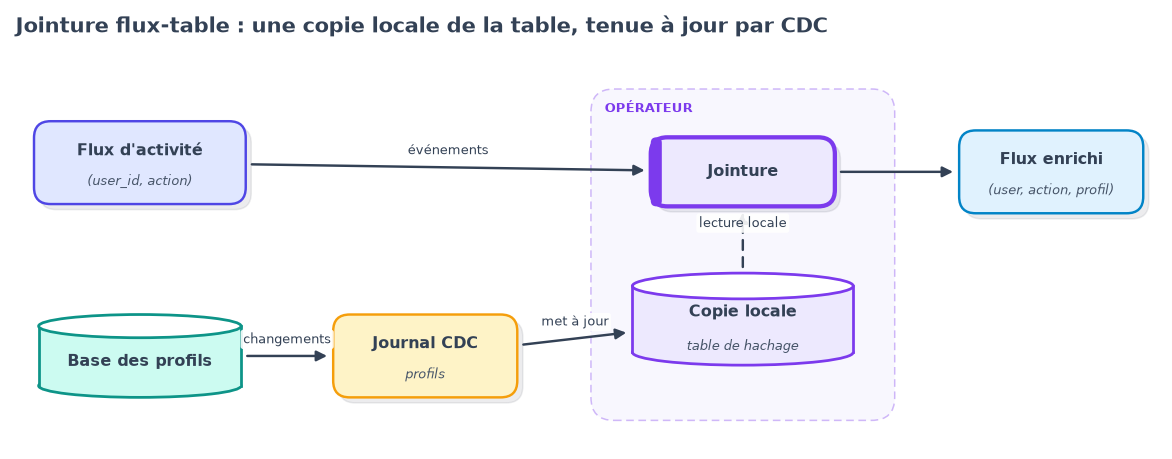

In [3]:
d = Diagram(12.5, 4.2, title="Jointure flux-table : une copie locale de la table, tenue à jour par CDC")
d.box("act", 1.4, 3.1, "Flux d'activité", sub="(user_id, action)", color=INDIGO, w=2.3)
d.box("db", 1.4, 1.0, "Base des profils", color=TEAL, kind="db", w=2.2, h=0.9)
d.box("cdc", 4.5, 1.0, "Journal CDC", sub="profils", color=AMBER, w=2.0)
d.group(6.3, 0.3, 9.6, 3.9, "opérateur", color=VIOLET)
d.box("ht", 7.95, 1.4, "Copie locale", sub="table de hachage", color=VIOLET, kind="db", w=2.4, h=1.0)
d.box("j", 7.95, 3.0, "Jointure", color=VIOLET, kind="model", w=2.0, h=0.75)
d.box("out", 11.3, 3.0, "Flux enrichi", sub="(user, action, profil)", color=SKY, w=2.0)
d.arrow("act", "j", "événements")
d.arrow("db", "cdc", "changements")
d.arrow("cdc", "ht", "met à jour")
d.arrow("ht", "j", "lecture locale", style="dashed")
d.arrow("j", "out")
d.show()

Ordre de grandeur : à 50 000 événements par seconde, une requête distante de 1 ms
exigerait 50 requêtes concurrentes en permanence (loi de Little) et 50 000 lectures par
seconde sur la base des profils ; une lecture dans une table de hachage locale prend
quelques centaines de nanosecondes. Démonstration avec `st.enrich` : un utilisateur
déménage au milieu de son activité.

In [4]:
flux = [("profile", "alice", {"ville": "Lyon"}), ("activity", "alice", "recherche vélo"),
        ("activity", "alice", "achat casque"), ("profile", "alice", {"ville": "Nantes"}),
        ("activity", "alice", "recherche ferry")]
pd.DataFrame(st.enrich(flux), columns=["utilisateur", "action", "profil au moment de la jointure"])

,utilisateur,action,profil au moment de la jointure
0,alice,recherche vélo,{'ville': 'Lyon'}
1,alice,achat casque,{'ville': 'Lyon'}
2,alice,recherche ferry,{'ville': 'Nantes'}


> **À retenir.** La jointure flux-table enrichit chaque événement avec une copie locale de
> la table, maintenue par CDC : c'est une jointure de deux flux, l'un sans fenêtre,
> l'autre avec une fenêtre infinie.

## 3. Jointure table-table (section *Table-table join (materialized view maintenance)*)

Retour aux timelines du chapitre 1 : plutôt que de fusionner à la lecture
les messages de tous les comptes suivis, on maintient pour chaque utilisateur un cache de
timeline, une « boîte de réception » où l'on écrit les messages à leur publication. Il
faut traiter quatre sortes d'événements : un nouveau message va dans la timeline de tous
les abonnés de son auteur ; un message supprimé en sort ; quand u1 se met à suivre u2,
les messages récents de u2 entrent dans la timeline de u1 ; quand il cesse, ils en
sortent. L'opérateur doit donc garder l'ensemble des abonnés de chaque utilisateur (et
les messages de chacun).

Vu autrement, il maintient la **vue matérialisée** d'une requête qui joint deux tables :

```sql
SELECT follows.follower_id AS timeline_id, posts.post_id
FROM posts JOIN follows ON follows.followee_id = posts.sender_id
```

Si un flux est la dérivée d'une table (cours 4) et une jointure un produit de deux tables
$u \cdot v$, le flux des changements de la vue suit la **règle du produit** :
$(u \cdot v)' = u'v + uv'$. Tout changement des messages est joint aux abonnés
**actuels**, tout changement des abonnements aux messages **actuels**. C'est exactement ce
que fait `st.TimelineView`. Vérifions-le contre la requête SQL exécutée sur les mêmes
tables, après 20 000 événements aléatoires.

In [5]:
db = sqlite3.connect(":memory:")
db.execute("CREATE TABLE posts (post_id INTEGER PRIMARY KEY, sender_id INTEGER)")
db.execute("CREATE TABLE follows (follower_id INTEGER, followee_id INTEGER, PRIMARY KEY (follower_id, followee_id))")
tv = st.TimelineView()
n_users, prochain_post = 200, 0
vivants = []
for _ in range(20_000):
    x = rng.random()
    if x < 0.45:
        a = int(rng.integers(0, n_users)); tv.apply("post", a, prochain_post)
        db.execute("INSERT INTO posts VALUES (?, ?)", (prochain_post, a)); vivants.append((a, prochain_post)); prochain_post += 1
    elif x < 0.5 and vivants:
        a, p = vivants.pop(int(rng.integers(0, len(vivants)))); tv.apply("delete_post", a, p)
        db.execute("DELETE FROM posts WHERE post_id = ?", (p,))
    elif x < 0.9:
        a, b = map(int, rng.integers(0, n_users, 2))
        if a != b:
            tv.apply("follow", a, b); db.execute("INSERT OR IGNORE INTO follows VALUES (?, ?)", (a, b))
    else:
        a, b = map(int, rng.integers(0, n_users, 2)); tv.apply("unfollow", a, b)
        db.execute("DELETE FROM follows WHERE follower_id = ? AND followee_id = ?", (a, b))
sql = {}
for f, p in db.execute("SELECT follows.follower_id, posts.post_id FROM posts JOIN follows ON follows.followee_id = posts.sender_id"):
    sql.setdefault(f, set()).add(p)
taille_vue = sum(len(v) for v in sql.values())
print(f"vue incrémentale identique à la requête SQL : {tv.view() == sql}")
print(f"taille de la vue : {taille_vue:,} lignes ; modifications élémentaires appliquées : {tv.writes:,}".replace(",", " "))
print(f"recalculer la jointure après chaque événement aurait produit ~{20_000 * taille_vue / 2:,.0f} lignes".replace(",", " "))

vue incrémentale identique à la requête SQL : True
taille de la vue : 281 236 lignes ; modifications élémentaires appliquées : 364 565
recalculer la jointure après chaque événement aurait produit ~2 812 360 000 lignes


La vue incrémentale coïncide avec la requête SQL ; elle n'a appliqué qu'un nombre de
modifications du même ordre que la taille finale de la vue, là où un recalcul après
chaque événement aurait produit des centaines de millions de lignes.

> **À retenir.** Une jointure table-table maintient la vue matérialisée de la jointure :
> chaque changement d'un côté est joint à l'état courant de l'autre (règle du produit).

## 4. La dépendance temporelle des jointures (section *Time-dependence of joins*)

Les trois jointures ont un point commun : l'opérateur garde un **état** issu d'une entrée
(recherches et clics, profils, abonnés) et l'interroge en traitant l'autre. L'**ordre**
des événements qui construisent cet état compte (suivre puis cesser de suivre n'est pas
l'inverse). Or un journal partitionné ordonne les événements d'une partition, **pas
ceux de flux ou de partitions différents**. Si un utilisateur modifie son profil au
moment où il agit, quelles activités sont jointes à l'ancien profil, lesquelles au
nouveau ? Si l'ordre entre les flux n'est pas déterminé, la jointure est
**non déterministe** : relancer le job sur la même entrée peut donner un autre résultat,
selon l'entrelacement des flux.

In [6]:
activites = [("activity", "bob", f"action {i}") for i in range(6)]
profils = [("profile", "bob", {"pays": "FR", "tva": 0.20}), ("profile", "bob", {"pays": "DE", "tva": 0.19})]
resultats = {}
for s in range(500):
    r = np.random.default_rng(s)
    a, p, fusion = list(activites), list(profils[1:]), [profils[0]]
    while a or p:                                    # entrelacement aléatoire, ordre préservé dans chaque flux
        if p and (not a or r.random() < 0.2):
            fusion.append(p.pop(0))
        else:
            fusion.append(a.pop(0))
    sortie = tuple(prof["pays"] for _, _, prof in st.enrich(fusion))
    resultats[sortie] = resultats.get(sortie, 0) + 1
pd.DataFrame([{"pays joint à chaque action": " ".join(k), "exécutions": v} for k, v in
              sorted(resultats.items(), key=lambda kv: -kv[1])]).set_index("pays joint à chaque action")

,exécutions
pays joint à chaque action,
FR FR FR FR FR FR,150
DE DE DE DE DE DE,81
FR FR DE DE DE DE,70
FR DE DE DE DE DE,63
FR FR FR DE DE DE,57
FR FR FR FR FR DE,40
FR FR FR FR DE DE,39


Le même couple de flux donne sept résultats différents selon l'entrelacement. Ce genre
de dépendance temporelle est partout : une facture doit appliquer le **taux de TVA en
vigueur à la date de la vente**, pas le taux actuel, ce qui compte quand on retraite des
données historiques. Les entrepôts de données appellent ce problème une **dimension à
évolution lente** (slowly changing dimension, SCD) et le résolvent en donnant un
identifiant à chaque **version** de l'enregistrement joint : chaque changement de taux
reçoit un nouvel identifiant, et la facture porte l'identifiant du taux au moment de la
vente. La jointure devient déterministe, mais la compaction devient impossible, puisqu'il
faut garder toutes les versions. Autre solution : dénormaliser, en mettant directement le
taux applicable dans chaque événement de vente.

In [7]:
taux_versions = {"tva-v1": 0.196, "tva-v2": 0.20}            # table versionnée : rien n'est écrasé
ventes = [{"ht": 100, "taux_id": "tva-v1", "date": "2013-12-30"}, {"ht": 100, "taux_id": "tva-v2", "date": "2014-01-02"}]
pd.DataFrame([{**v, "ttc": v["ht"] * (1 + taux_versions[v["taux_id"]])} for v in ventes])

,ht,taux_id,date,ttc
0,100,tva-v1,2013-12-30,119.6
1,100,tva-v2,2014-01-02,120.0


> **À retenir.** Joindre à un état qui change pose la question « à quel instant ? ». Sans
> ordre défini entre les flux, la jointure n'est pas déterministe ; versionner
> l'enregistrement joint (SCD) ou dénormaliser la rend reproductible.

## 5. Micro-lots et points de contrôle (section *Microbatching and checkpointing*)

Un framework par lots tolère facilement les pannes : une tâche qui échoue est relancée
ailleurs et sa sortie partielle est jetée, ce qui est possible parce que les entrées sont
immuables, que chaque tâche écrit dans son propre fichier, et que la sortie ne devient
visible qu'à la fin. Le résultat est le même que sans panne : tout se passe comme si
chaque enregistrement avait été traité **exactement une fois** (exactly-once ; le livre
note que « effectivement une fois », effectively-once, serait plus exact). En flux,
attendre la fin d'une tâche pour rendre sa sortie visible est impossible : un flux ne
finit jamais.

**Micro-lots.** On découpe le flux en petits blocs traités chacun comme un mini job par
lots (Spark Streaming, avec des lots d'environ une seconde). Le choix de la taille est un
compromis : des lots plus petits coûtent plus en ordonnancement et coordination, des lots
plus grands retardent les résultats. Modélisons un surcoût fixe $o = 50$ ms par lot et un
coût de 10 µs par événement : avec $\lambda$ événements par seconde et des lots de $b$
secondes, il faut $o + \lambda b s \le b$, soit $b \ge o / (1 - \lambda s)$, et la latence
moyenne vaut à peu près $b/2 + o + \lambda b s$.

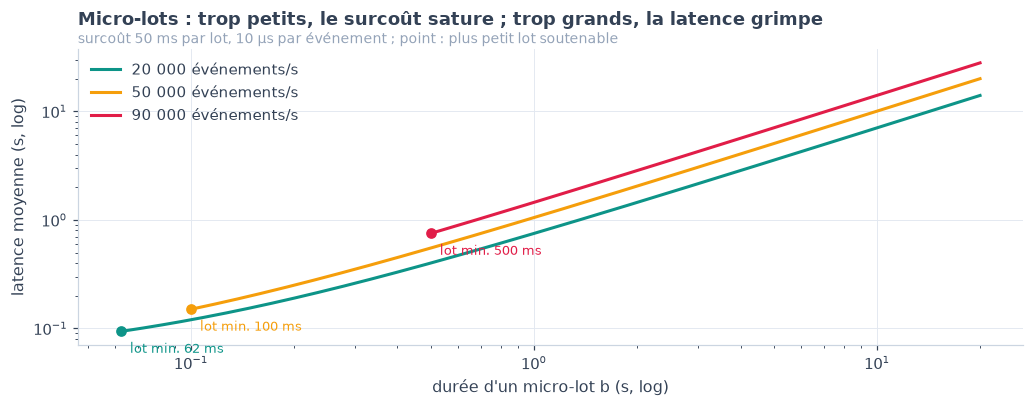

In [8]:
o, s_ev = 0.05, 10e-6
b = np.logspace(-2, 1.3, 300)
fig, ax = plt.subplots(figsize=(9.5, 3.8))
for lam, c in [(20_000, TEAL), (50_000, AMBER), (90_000, ROSE)]:
    lat = b / 2 + o + lam * b * s_ev
    ok = o + lam * b * s_ev <= b
    ax.plot(b[ok], lat[ok], color=c, label=f"{lam:,} événements/s".replace(",", " "))
    bmin = o / (1 - lam * s_ev)
    ax.plot([bmin], [bmin / 2 + o + lam * bmin * s_ev], "o", color=c)
    ax.annotate(f"lot min. {bmin * 1000:.0f} ms", (bmin, bmin / 2 + o + lam * bmin * s_ev), (6, -14),
                textcoords="offset points", fontsize=8.5, color=c)
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("durée d'un micro-lot b (s, log)"); ax.set_ylabel("latence moyenne (s, log)")
ax.set_title("Micro-lots : trop petits, le surcoût sature ; trop grands, la latence grimpe")
subtitle(ax, "surcoût 50 ms par lot, 10 µs par événement ; point : plus petit lot soutenable")
ax.legend()
plt.tight_layout(); plt.show()

Plus la charge approche de la capacité ($\lambda s \to 1$), plus le plus petit lot
soutenable grandit : à 90 000 événements par seconde, il faut des lots d'une demi-seconde.
Le micro-lot impose aussi implicitement une fenêtre fixe égale à sa durée, en temps de
traitement ; les fenêtres plus longues doivent reporter leur état d'un lot à l'autre.

**Points de contrôle.** Variante d'Apache Flink : produire périodiquement des
**checkpoints** de l'état, écrits sur un stockage durable. Après une panne, l'opérateur
repart du dernier checkpoint et jette la sortie produite depuis. Les checkpoints sont
déclenchés par des **barrières** insérées dans le flux, comparables aux frontières des
micro-lots, mais sans imposer de taille de fenêtre.

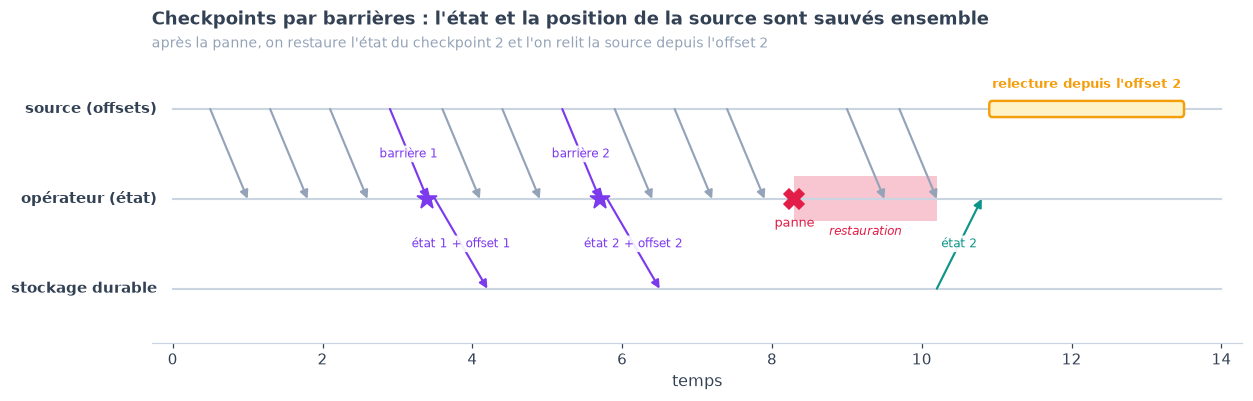

In [9]:
stt = SpaceTime(["source (offsets)", "opérateur (état)", "stockage durable"], t_max=14, width=11.5,
                title="Checkpoints par barrières : l'état et la position de la source sont sauvés ensemble",
                subtitle="après la panne, on restaure l'état du checkpoint 2 et l'on relit la source depuis l'offset 2")
for t in [0.5, 1.3, 2.1, 3.6, 4.4, 5.9, 6.7, 7.4, 9.0, 9.7]:
    stt.msg("source (offsets)", t, "opérateur (état)", t + 0.5, "", color=GRAY)
for t, k in [(2.9, 1), (5.2, 2)]:
    stt.msg("source (offsets)", t, "opérateur (état)", t + 0.5, f"barrière {k}", color=VIOLET)
    stt.event("opérateur (état)", t + 0.5, "", kind="star", color=VIOLET)
    stt.msg("opérateur (état)", t + 0.6, "stockage durable", t + 1.3, f"état {k} + offset {k}", color=VIOLET)
stt.event("opérateur (état)", 8.3, "panne", kind="crash")
stt.span("opérateur (état)", 8.3, 10.2, "restauration", color=ROSE)
stt.msg("stockage durable", 10.2, "opérateur (état)", 10.8, "état 2", color=TEAL)
stt.op("source (offsets)", 10.9, 13.5, "relecture depuis l'offset 2", color=AMBER)
stt.show()

Combien de fois sauver l'état ? Un checkpoint coûte $C$ (temps de pause ou ressources) ;
une panne survient en moyenne tous les MTBF et fait refaire en moyenne la moitié de
l'intervalle $T$. Le surcoût relatif vaut environ $C/T + T/(2\,\text{MTBF})$, minimal pour
$T^* = \sqrt{2\,C\,\text{MTBF}}$ (formule de Young, `st.young_interval`).

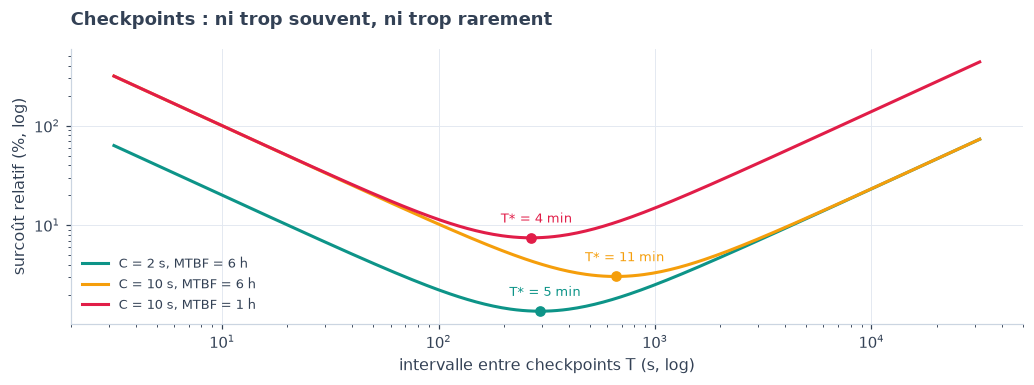

In [10]:
T = np.logspace(0.5, 4.5, 300)
fig, ax = plt.subplots(figsize=(9.5, 3.6))
for C, mtbf, c in [(2, 6 * 3600, TEAL), (10, 6 * 3600, AMBER), (10, 3600, ROSE)]:
    cout = C / T + T / (2 * mtbf)
    ts = st.young_interval(C, mtbf)
    ax.plot(T, cout * 100, color=c, label=f"C = {C} s, MTBF = {mtbf / 3600:g} h")
    ax.plot([ts], [(C / ts + ts / (2 * mtbf)) * 100], "o", color=c)
    ax.annotate(f"T* = {ts / 60:.0f} min", (ts, (C / ts + ts / (2 * mtbf)) * 100), (-20, 10),
                textcoords="offset points", fontsize=8.5, color=c)
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("intervalle entre checkpoints T (s, log)"); ax.set_ylabel("surcoût relatif (%, log)")
ax.set_title("Checkpoints : ni trop souvent, ni trop rarement")
ax.legend(fontsize=8.5)
plt.tight_layout(); plt.show()

Dans le périmètre du framework, micro-lots et checkpoints offrent la même sémantique
« exactement une fois » que le traitement par lots. Mais dès que la sortie **quitte** le
framework (écriture dans une base, message vers un courtier externe, envoi d'un
courriel), on ne peut plus jeter la sortie d'un lot échoué : relancer la tâche refait
l'effet de bord.

> **À retenir.** Micro-lots et checkpoints découpent le flux en unités rejouables ; leur
> fréquence arbitre entre surcoût et latence (ou travail perdu). Ils ne suffisent pas pour
> les effets de bord externes.

## 6. La validation atomique revisitée (section *Atomic commit revisited*)

Pour donner l'apparence d'un traitement exactement une fois malgré les pannes, toutes les
sorties et tous les effets du traitement d'un événement doivent être conservés **si et
seulement si** le traitement réussit : messages vers les opérateurs suivants ou vers
l'extérieur, écritures en base, changements d'état de l'opérateur, et acquittement de
l'entrée (l'avance de l'offset). Tout ou rien : c'est la validation atomique du chapitre
9. Les transactions XA hétérogènes ont leurs problèmes, mais dans un
environnement restreint on sait l'implémenter efficacement : Google Cloud Dataflow,
VoltDB et Kafka gardent les transactions **internes** au framework (état et messages
gérés ensemble) et amortissent le protocole sur plusieurs messages par transaction.

Comparons quatre stratégies sur un job qui compte des événements par clé dans une base
externe, avec trois pannes injectées (`st.run_stateful_job`).

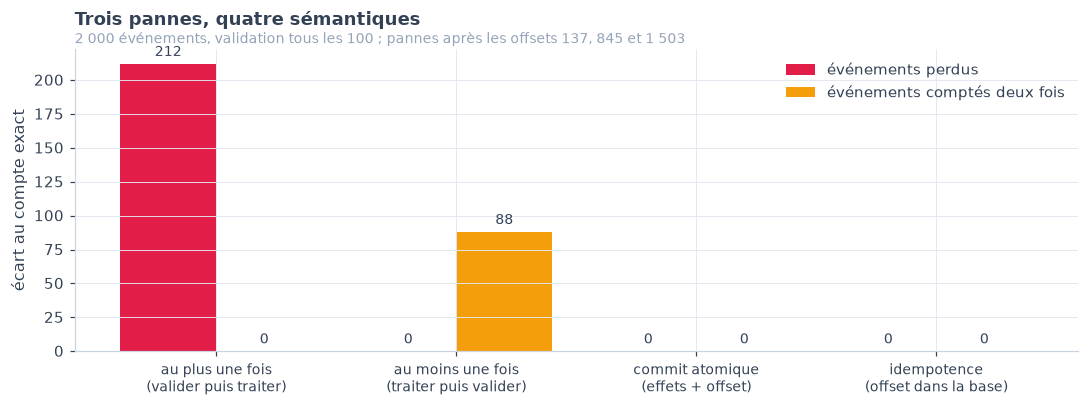

In [11]:
cles = list(rng.integers(0, 8, 2000))
pannes = [137, 845, 1503]
modes = {"at_most_once": "au plus une fois\n(valider puis traiter)", "at_least_once": "au moins une fois\n(traiter puis valider)",
         "transactional": "commit atomique\n(effets + offset)", "idempotent": "idempotence\n(offset dans la base)"}
R = {m: st.run_stateful_job(cles, m, pannes, commit_every=100) for m in modes}
fig, ax = plt.subplots(figsize=(10, 3.8))
x = np.arange(len(modes))
ax.bar(x - 0.2, [R[m]["missing"] for m in modes], 0.4, color=ROSE, label="événements perdus")
ax.bar(x + 0.2, [R[m]["excess"] for m in modes], 0.4, color=AMBER, label="événements comptés deux fois")
annotate_bars(ax, "{:.0f}")
ax.set_xticks(x, list(modes.values()), fontsize=9)
ax.set_ylabel("écart au compte exact")
ax.set_title("Trois pannes, quatre sémantiques")
subtitle(ax, "2 000 événements, validation tous les 100 ; pannes après les offsets 137, 845 et 1 503")
ax.legend()
plt.tight_layout(); plt.show()

« Au moins une fois » recompte, à chaque panne, les messages traités depuis la dernière
validation (38, 46 et 4, soit 88) ; « au plus une fois » perd au contraire la fin du lot
déjà validé mais pas encore traité (62, 54 et 96, soit 212). Le commit atomique et
l'idempotence donnent le compte exact.

> **À retenir.** « Exactement une fois » exige que les effets d'un événement et
> l'avance de l'offset soient validés ensemble : par une transaction interne au framework,
> ou par l'idempotence.

## 7. L'idempotence (section *Idempotence*)

Le but est de pouvoir rejouer sans risque une tâche échouée. Une autre voie que la
transaction est l'**idempotence** : une opération idempotente
a le même effet qu'on l'exécute une ou plusieurs fois. Supprimer une clé est idempotent,
incrémenter un compteur ne l'est pas. On rend souvent une opération idempotente avec un
peu de métadonnées : l'offset Kafka d'un message est persistant et croissant ; en
écrivant dans une base externe, on stocke avec la valeur l'offset du message qui l'a
produite, et l'on ignore un message dont l'offset est déjà appliqué (c'est le mode
`idempotent` ci-dessus ; l'état de Trident, dans Storm, repose sur la même idée).

Cela suppose : que le rejeu présente **les mêmes messages dans le même ordre** (un journal
le garantit), que le traitement soit **déterministe**, et qu'**aucun autre nœud** ne
modifie la même valeur en même temps. Ce dernier point demande du **fencing** lors d'une
reprise (chapitre 8) : un nœud que l'on croit mort mais qui est vivant (pause
du ramasse-miettes, réseau coupé) ne doit pas pouvoir écrire après son remplaçant.

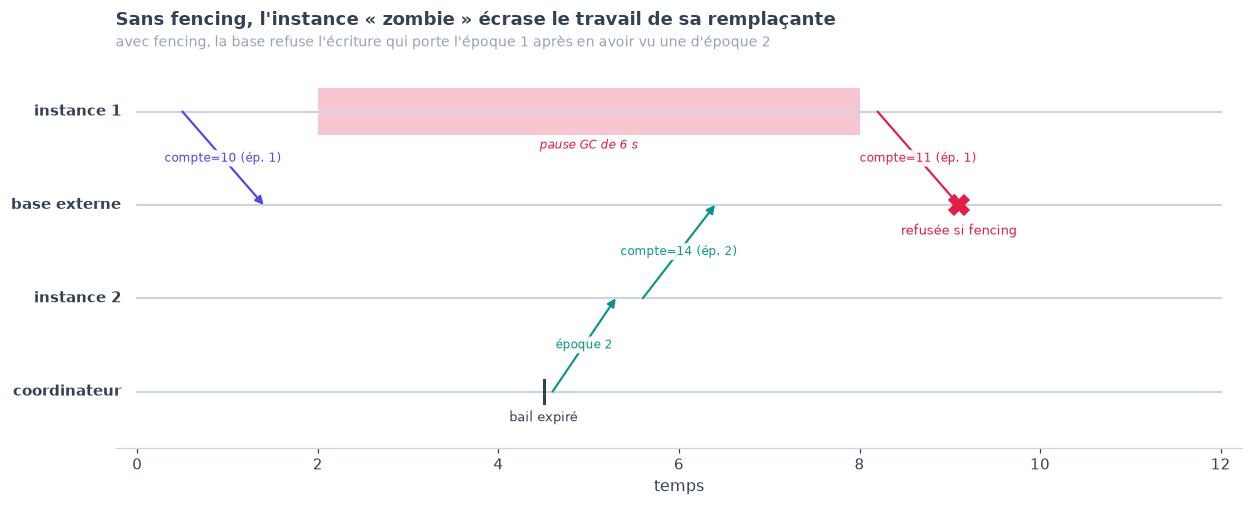

In [12]:
stt = SpaceTime(["instance 1", "base externe", "instance 2", "coordinateur"], t_max=12, width=11.5,
                title="Sans fencing, l'instance « zombie » écrase le travail de sa remplaçante",
                subtitle="avec fencing, la base refuse l'écriture qui porte l'époque 1 après en avoir vu une d'époque 2")
stt.msg("instance 1", 0.5, "base externe", 1.4, "compte=10 (ép. 1)", color=INDIGO)
stt.span("instance 1", 2.0, 8.0, "pause GC de 6 s", color=ROSE)
stt.event("coordinateur", 4.5, "bail expiré", kind="tick")
stt.msg("coordinateur", 4.6, "instance 2", 5.3, "époque 2", color=TEAL)
stt.msg("instance 2", 5.6, "base externe", 6.4, "compte=14 (ép. 2)", color=TEAL)
stt.msg("instance 1", 8.2, "base externe", 9.1, "compte=11 (ép. 1)", color=ROSE)
stt.event("base externe", 9.1, "refusée si fencing", kind="crash", color=ROSE)
stt.show()

In [13]:
rows = []
for fencing in (False, True):
    base = st.FencedSink(fencing=fencing)
    base.write("compte", 10, epoch=1)
    base.write("compte", 14, epoch=2)                      # la remplaçante a retraité et avancé
    base.write("compte", 11, epoch=1)                      # le zombie se réveille avec un état périmé
    rows.append({"fencing": fencing, "valeur finale": base.data["compte"], "écritures refusées": base.rejected})
pd.DataFrame(rows).set_index("fencing")

,valeur finale,écritures refusées
fencing,,
False,11,0
True,14,1


> **À retenir.** Avec des métadonnées (l'offset du dernier message appliqué), une
> écriture devient idempotente et le rejeu sans danger, à condition d'un rejeu identique,
> d'un traitement déterministe et d'un fencing contre les instances zombies.

## 8. Reconstruire l'état après une panne (section *Rebuilding state after a failure*)

Tout opérateur à état (agrégats fenêtrés, tables et index des jointures) doit pouvoir
retrouver cet état après une panne. Les options :

- garder l'état dans une **base distante répliquée** : simple, mais une requête réseau par
  message coûte cher ;
- garder l'état **local** et le **répliquer périodiquement** : Flink écrit des instantanés
  de l'état des opérateurs sur un stockage durable ; Samza et Kafka Streams envoient
  chaque changement d'état dans un sujet Kafka **compacté** dédié, comme de la CDC ;
  VoltDB traite chaque message de façon redondante sur plusieurs nœuds ;
- parfois, **ne rien répliquer** : un agrégat sur une fenêtre courte se reconstruit en
  rejouant les événements de la fenêtre ; une copie locale de base maintenue par CDC se
  reconstruit depuis le sujet compacté.

Le meilleur choix dépend des performances de l'infrastructure (sur certains systèmes, le
réseau a moins de latence que le disque et un débit comparable). Ordres de grandeur du
temps de reprise pour un état de 20 Go :

In [14]:
etat_go = 20
options = pd.DataFrame({
    "débit de lecture (Mo/s)": [500, 100, 100],
    "volume à lire (Go)": [etat_go, etat_go * 1.5, 50 * 3600 * 1e3 * 1e-9 * 200],
}, index=["instantané sur stockage durable", "sujet compacté (≈ 1,5 × l'état)",
          "rejouer 1 h d'entrée (50 000 év./s × 200 o)"])
options["temps de reprise (min)"] = options["volume à lire (Go)"] * 1e3 / options["débit de lecture (Mo/s)"] / 60
options.round(1)

,débit de lecture (Mo/s),volume à lire (Go),temps de reprise (min)
instantané sur stockage durable,500,20.0,0.7
"sujet compacté (≈ 1,5 × l'état)",100,30.0,5.0
rejouer 1 h d'entrée (50 000 év./s × 200 o),100,36.0,6.0


Lire un instantané compact est le plus rapide ; relire un sujet compacté (qui contient
encore quelques versions obsolètes) prend quelques minutes ; rejouer l'entrée n'est
raisonnable que si la fenêtre est courte. Aucune solution n'est idéale partout, et le
meilleur compromis évolue avec les technologies de stockage et de réseau.

> **À retenir.** L'état d'un opérateur se reconstruit depuis un instantané, un journal de
> changements compacté ou un rejeu de l'entrée ; le choix dépend de la taille de l'état,
> de la fenêtre et des débits disponibles.

## Synthèse

- Trois jointures : **flux-flux** (fenêtre sur les deux flux, état ≈ débit × fenêtre),
  **flux-table** (copie locale tenue à jour par CDC), **table-table** (vue matérialisée de
  la jointure, règle du produit).
- Joindre à un état qui change rend le résultat **dépendant de l'ordre** des flux ; les
  versions (SCD) ou la dénormalisation le rendent déterministe.
- La tolérance aux pannes vise « exactement une fois », plus justement **effectivement
  une fois** : micro-lots et **checkpoints** dans le framework, **commit atomique** interne
  ou **idempotence** (avec fencing) pour les effets externes.
- L'état se reconstruit par instantané, journal compacté ou rejeu.
- Liens : jointures par lots (chapitre 10), timelines (chapitre
  1), validation atomique (chapitre 9), baux et fencing
  (chapitre 8), exécution réellement série (chapitre 7). Le
  chapitre 12 élargit ces idées à l'architecture de systèmes entiers.